# Analysis of Relational Attention
The purpose of this notebook is to analyze the linear relational attention head trained in the `model_training.ipynb`.

## Imports

In [1]:
import torch
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from relational_attention.models import RelationalAttentionHead, AttentionClassifier

In [2]:
torch.manual_seed(42)

## Load model

In [3]:
checkpoint = torch.load("../../data/linear_relational_attention_block_classifier_full.pt", map_location="cpu")

In [4]:
# Recreate the same architecture
model = AttentionClassifier(
    embed_dim=checkpoint["metadata"]["embed_dim"],
    head_dim=checkpoint["metadata"]["head_dim"],
    attn_cls=RelationalAttentionHead,
    context_size=checkpoint["metadata"]["context_size"],
    linear=True
)
model.load_state_dict(checkpoint["model_state"])
model.eval()

AttentionClassifier(
  (attn): RelationalAttentionHead(
    (W_q): Linear(in_features=6, out_features=6, bias=False)
    (W_k): Linear(in_features=6, out_features=6, bias=False)
  )
  (fc): Linear(in_features=24, out_features=1, bias=True)
)

## Visualize query, key, value matrices

In [5]:
attn_head = model.attn
Q_weights = attn_head.W_q.weight.data
K_weights = attn_head.W_k.weight.data
V_matrix = attn_head.V.data

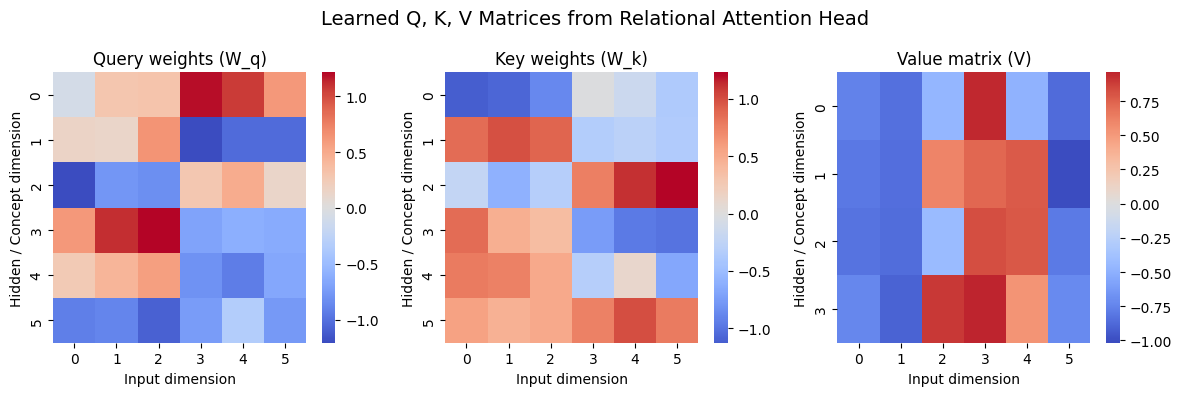

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap(Q_weights, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Query weights (W_q)")

sns.heatmap(K_weights, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Key weights (W_k)")

sns.heatmap(V_matrix, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Value matrix (V)")

for ax in axes:
    ax.set_xlabel("Input dimension")
    ax.set_ylabel("Hidden / Concept dimension")

plt.suptitle("Learned Q, K, V Matrices from Relational Attention Head", fontsize=14)
plt.tight_layout()
plt.show()

## Covariance structure of the matrices

In [7]:
def covariance(matrix):
    # subtract mean for proper covariance
    matrix_centered = matrix - matrix.mean(axis=0, keepdims=True)
    return np.cov(matrix_centered.T)  # (D, D)

In [8]:
cov_q = covariance(Q_weights)
cov_k = covariance(K_weights)
cov_v = covariance(V_matrix)

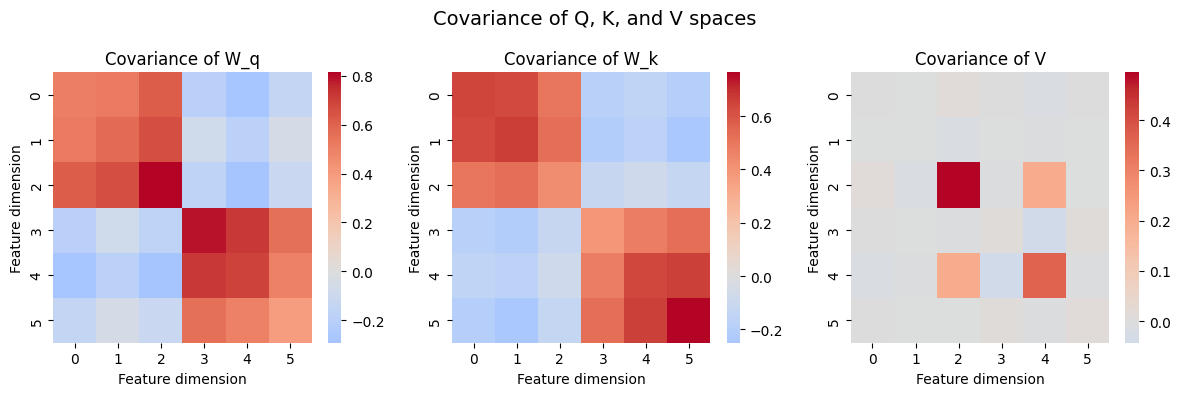

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap(cov_q, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Covariance of W_q")

sns.heatmap(cov_k, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Covariance of W_k")

sns.heatmap(cov_v, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Covariance of V")

for ax in axes:
    ax.set_xlabel("Feature dimension")
    ax.set_ylabel("Feature dimension")

plt.suptitle("Covariance of Q, K, and V spaces", fontsize=14)
plt.tight_layout()
plt.savefig('../../results/relational_attention_covariance.png')
plt.show()

- **Q–K subspaces** organize into structured, correlated blocks — indicating the model learns _block-level comparison spaces_ rather than raw input features.
    
- **V (value) matrix** is sparse and low-rank — encoding _relational prototypes_ rather than perceptual or block identities.
    
- High Q–K dot products → access the **“identity”** prototype in V; low dot products → access the **“non-identity”** prototype.
    
- The **attention mechanism** transforms similarity structure (Q–K alignments) into **discrete relational tokens** (“same” vs. “different”).
    
- The **linear decoder** simply checks for consistency among accessed value tokens — if all are identical → “same block”; if any differ → “different blocks.”